# Rekonstruktion aus unvollständigen Messungen

Ein Bild aus wenigen Fourier-Komponenten, ein Quantenzustand aus wenigen Pauli-Messungen, ein Signal aus wenigen Summen: Oft gibt es weniger Messungen als Unbekannte, und trotzdem lässt sich das Objekt zurückrechnen, wenn man etwas über seine Struktur weiß. Das Notebook zeigt das mit derselben Mathematik in drei Gebieten: Compressed Sensing an einem künstlichen Signal, ein Bild von M 87* an der echten Abdeckung des Event Horizon Telescope (öffentliche Daten von 2017) und Quantenzustände aus simulierten Messungen. Der Code steht in [`code/`](https://github.com/deltorobarba/science/tree/main/code) (`sensing.py` für die ℓ1-Verfahren, `eht.py` für die EHT-Daten und die Bilder, `tomography.py` für die Quantenzustände); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Einführung: weniger Gleichungen als Unbekannte**

Ein kleines Beispiel zuerst. Gesucht sind drei Zahlen, gemessen werden nur zwei Summen: $x_1 + x_2 = 1$ und $x_2 + x_3 = 1$. Jedes $x = (1-t,\ t,\ 1-t)$ erfüllt beide, es gibt unendlich viele Lösungen. Die übliche Wahl ist die kürzeste, mit der kleinsten Norm $\lVert x\rVert_2$ (Pseudoinverse, kleinste Quadrate): $(\tfrac13, \tfrac23, \tfrac13)$. Sie verteilt den Wert auf alle Einträge. Weiß man aber, dass nur ein Eintrag nicht null ist, bleibt genau $(0, 1, 0)$. Diese Lösung findet man ohne Suchen: Sie hat die kleinste Betragssumme $\lVert x\rVert_1 = \vert 1-t\vert + \vert t\vert + \vert 1-t\vert$, die für $0 \le t \le 1$ gleich $2 - t$ ist und bei $t = 1$ am kleinsten wird.

Allgemein ist ein Objekt $x$ mit $n$ Zahlen gesucht (Pixel eines Bildes, Einträge einer Matrix), gemessen werden $m < n$ lineare Kombinationen mit Rauschen:

$$y = A\,x + \varepsilon, \qquad A \in \mathbb{R}^{m \times n}.$$

Die Lösungen von $A x = y$ bilden einen Raum mit $n - m$ Dimensionen. Welche man nimmt, entscheidet das Vorwissen über $x$, in der Sprache des Machine Learning der Prior oder Regularisierer:

- **Kleinste Energie**, $\hat x = A^{+} y$: die Baseline. Was nicht gemessen wurde, wird mit null gefüllt, und das Objekt verschmiert.
- **Dünnbesetzt**: $\min \lVert x\rVert_1$ unter $A x = y$ (Basis Pursuit), bei Rauschen $\min_x \tfrac12 \lVert A x - y\rVert_2^2 + \lambda \lVert x\rVert_1$ (LASSO). Die $\ell_1$-Kugel hat Ecken auf den Achsen, und der Lösungsraum berührt sie meist zuerst in einer Ecke, also in einem Punkt mit vielen Nullen (Bild in Schritt 1).
- **Niedriger Rang** bei Matrizen: Ein reiner Quantenzustand $\rho = \vert\psi\rangle\langle\psi\vert$ hat Rang 1. Statt vieler Nullen in $x$ hat $\rho$ viele Eigenwerte null.

Wie viele Messungen braucht man? Nicht $n$, sondern etwas mehr, als die Struktur Freiheitsgrade hat. Ein Signal mit $k$ von $n$ Einträgen ungleich null hat $k$ Werte und eine von $\binom{n}{k}$ möglichen Lagen, das sind etwa $k \log(n/k)$ Bits. Für zufällige Messmatrizen genügen tatsächlich $m \approx C\,k \log(n/k)$ Messungen (Candès, Romberg und Tao; Donoho; beide 2006). Die Beispiele des Notebooks und was im Lauf gereicht hat:

| Gebiet (Schritt) | Objekt | Messung | Vorwissen | Was gereicht hat |
|---|---|---|---|---|
| Mathematik (1, 2) | Signal mit 200 Zahlen | zufällige Summen | 8 Einträge ungleich null | 40 Summen (exakt) |
| Astrophysik (3, 4) | Bild von M 87*, 4096 Pixel | Fourier-Komponenten an 21 Basislinien | Helligkeit ≥ 0, wenige helle Pixel | 111 Fourier-Punkte einer Nacht (Korrelation 0.94) |
| Quantenphysik (5) | 5 Qubits, 1023 Pauli-Erwartungswerte | einzelne Erwartungswerte | Rang 1, also 62 Parameter | 250 Erwartungswerte (Fidelity 1.00) |
| Quantenphysik (6) | 10 Qubits, über eine Million Erwartungswerte | zufällige Einzel-Qubit-Messungen | nur einige Eigenschaften gesucht | 2000 Schnappschüsse für 45 Korrelationen (Fehler 0.05) |

In den ersten drei Zeilen braucht man ein kleines Vielfaches der Freiheitsgrade, in der letzten hängt die Zahl der Messungen nur von der Frage ab.

In [1]:
import sys
import urllib.request
from pathlib import Path

CODE = Path.cwd() / "code"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir()
    for f in ["sensing.py", "eht.py", "tomography.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner "code" direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import sensing, eht, tomography
DATA = Path.cwd() / "data" / "reconstruction"          # Cache für die EHT-Dateien

**1. Ein dünnbesetztes Signal aus zu wenigen Summen**

Ein Signal mit $n = 200$ Einträgen, von denen nur $k = 8$ nicht null sind, wird mit $m = 60$ zufälligen Summen gemessen (Gauß-Matrix $A$, ohne Rauschen). Zurückgerechnet wird zweimal: mit der kleinsten $\ell_2$-Norm über die Pseudoinverse (`sensing.min_norm`) und mit der kleinsten $\ell_1$-Norm als lineares Programm (`sensing.basis_pursuit`, scipy mit HiGHS). Links steht dasselbe in zwei Dimensionen: Eine Messung $0.4\,x_1 + x_2 = 1$ lässt eine ganze Gerade von Lösungen offen.

Links berührt die Gerade der Lösungen die kleinste $\ell_2$-Kugel (Kreis) in $(0.34, 0.86)$, einem Punkt mit zwei Einträgen ungleich null, und die kleinste $\ell_1$-Kugel (Raute) in ihrer Ecke $(0, 1)$. Rechts dasselbe in 200 Dimensionen: Die $\ell_2$-Lösung erfüllt alle 60 Messungen, verteilt aber kleine Werte auf alle 200 Einträge und trifft die wahren Werte kaum (relativer Fehler 87.3 %). Die $\ell_1$-Lösung findet genau die 8 Einträge (Fehler 0.0 %). Mit `M = 40` gelingt das noch, mit `M = 30` nicht mehr (Fehler 42 %); wo die Grenze liegt, zeigt Schritt 2.

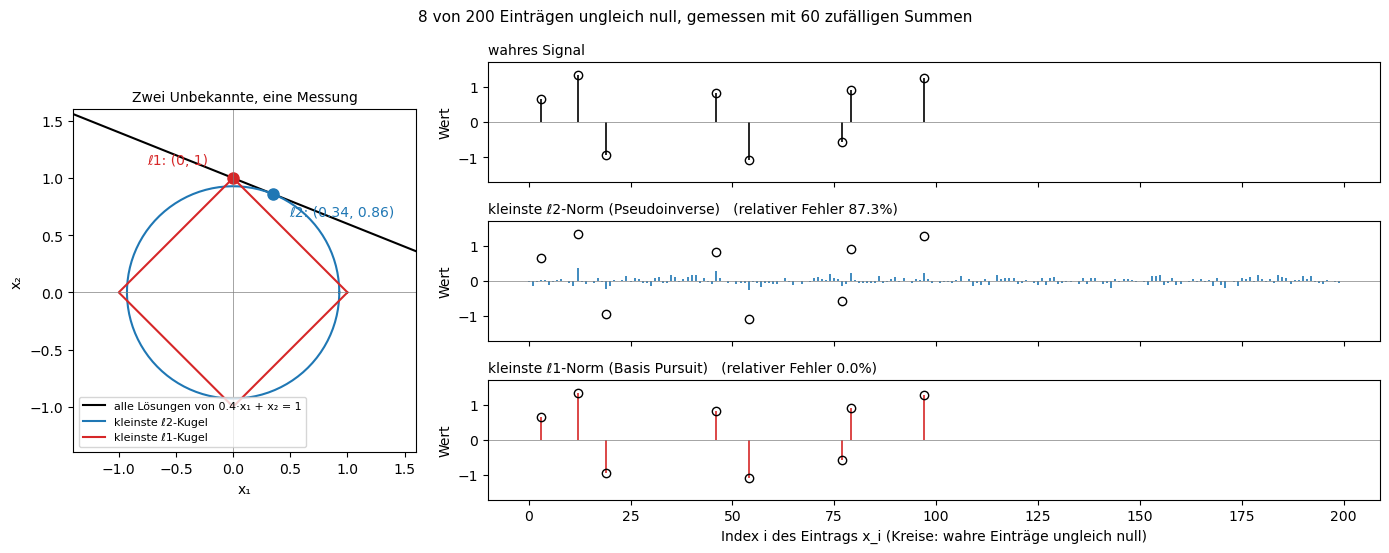

In [2]:
N, K, M = 200, 8, 60          # Unbekannte, Einträge ungleich null, Messungen
A, x, y = sensing.problem(N, K, M, seed=1)
estimates = {"kleinste ℓ2-Norm (Pseudoinverse)": sensing.min_norm(A, y),
             "kleinste ℓ1-Norm (Basis Pursuit)": sensing.basis_pursuit(A, y)}
sensing.plot_recovery(x, estimates, f"{K} von {N} Einträgen ungleich null, gemessen mit {M} zufälligen Summen")

**2. Wie viele Messungen? Der Phasenübergang**

Für $n = 100$ Unbekannte und $k = 5$, 10 und 20 Einträge ungleich null wird die Zahl der Messungen $m$ von 4 bis 100 erhöht, mit je 25 zufälligen Problemen, und gezählt, wie oft Basis Pursuit das Signal exakt findet (relativer Fehler unter $10^{-4}$). Das ist die Frage des Notebooks in ihrer einfachsten Form: Ab wie vielen Messungen reicht die Information?

Der Übergang ist scharf: Unterhalb einer Schwelle gelingt fast nichts, wenige Messungen darüber fast alles. Die Hälfte der Versuche gelingt ab etwa 19, 32 und 52 Messungen, also beim 3.9-, 3.2- und 2.6-Fachen von $k$ und weit unter $n = 100$. Je dünner das Signal, desto größer der Faktor, ähnlich wie $\ln(n/k)$ (3.0, 2.3 und 1.6) in der Formel $m \approx C\,k \log(n/k)$. Gestrichelt ist die harte Untergrenze $m = k$: Mit weniger Messungen als unbekannten Werten geht es auch dann nicht, wenn man weiß, wo die Einträge liegen.

k =  5: Hälfte exakt ab m ≈ 19 Messungen = 3.9 · k  (ln(n/k) = 3.0)
k = 10: Hälfte exakt ab m ≈ 32 Messungen = 3.2 · k  (ln(n/k) = 2.3)
k = 20: Hälfte exakt ab m ≈ 52 Messungen = 2.6 · k  (ln(n/k) = 1.6)


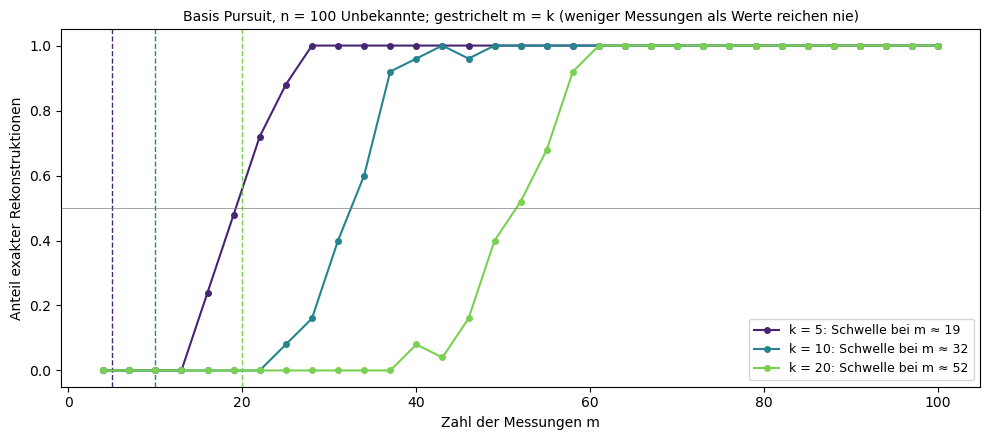

In [3]:
N, KS, TRIALS = 100, [5, 10, 20], 25     # Unbekannte, Einträge ungleich null, Versuche je Punkt
MS = list(range(4, N + 1, 3))           # Zahl der Messungen
rate, m50 = sensing.phase_transition(N, KS, MS, trials=TRIALS)
sensing.plot_transition(N, KS, MS, rate, m50)

**3. Was das Event Horizon Telescope misst**

Das EHT verbindet Radioteleskope auf vier Kontinenten. Jedes Paar (eine Basislinie) misst kein Pixel, sondern eine Fourier-Komponente des Himmelsbildes, die Visibility $V(u, v) = \sum_{l,m} I(l, m)\, e^{-2\pi i (u l + v m)}$; dabei ist $(u, v)$ die Basislinie in Wellenlängen, senkrecht zur Blickrichtung projiziert. Das ist $y = A x$ mit einer Fourier-Matrix $A$, die nur die gemessenen Punkte enthält. Geladen werden die öffentlichen Daten von M 87* aus vier Nächten im April 2017 (`eht.load`), und angepasst wird das einfachste Vorwissen: ein Ring mit drei Zahlen (Fluss, Durchmesser, Breite), dessen Amplitude eine Bessel-Funktion $J_0$ ist (`eht.fit_ring`).

Die Ausgabe zählt 51 119 Visibilities auf 21 Basislinien zwischen 7 Stationen. Die längste Basislinie hat 8.33 Gλ, bei 1.3 mm Wellenlänge rund 11 000 km, das gibt eine Auflösung von etwa 25 µas. Links sieht man, wie dünn die Fourier-Ebene besetzt ist: Jede Basislinie zieht durch die Erdrotation einen Bogen, dazwischen bleiben große Lücken. Rechts fällt die Amplitude mit der Länge der Basislinie, geht bei 3.60 Gλ fast auf null und steigt danach wieder an, wie die Bessel-Funktion eines Rings. Die wenigen Punkte nahe 0 Gλ (Stationen am selben Ort) liegen höher, weil sie auch den Jet sehen; sie bleiben im Fit weg. Das Modell mit drei Zahlen ergibt 43.8 µas Durchmesser (die EHT-Kollaboration gibt 42 ± 3 µas an). Für den Durchmesser reichen die Messungen also, für ein Bild mit 4096 Pixeln fehlen die meisten Fourier-Komponenten.

51 119 Visibilities aus 8 Dateien, 21 Basislinien zwischen 7 Stationen
Längste Basislinie 8.33 Gλ, also Auflösung λ/B ≈ 25 µas


Ringmodell an 45 623 Amplituden: Durchmesser 43.8 µas, Breite 3.3 µas, Fluss 0.30 Jy; erste Nullstelle bei 3.60 Gλ


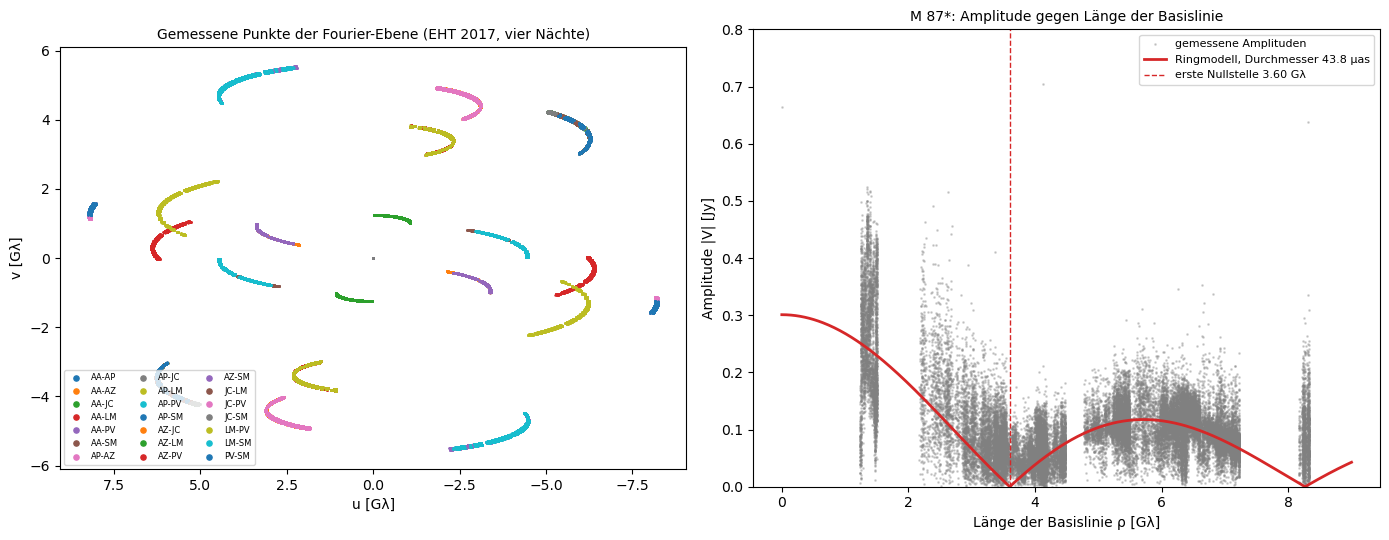

In [4]:
df = eht.load(DATA / "eht")       # 8 Dateien, zusammen etwa 4 MB, beim ersten Lauf aus dem Internet
fit = eht.fit_ring(df)            # Ringmodell an die Amplituden auf Basislinien über 1 Gλ
eht.plot_data(df, fit)

**4. Ein Bild aus der Abdeckung: Dirty Image, CLEAN und ℓ1**

Die echten Phasen sind von der Atmosphäre verfälscht, deshalb wird hier ein Modellbild an der echten Abdeckung „gemessen“: ein Ring mit dem Durchmesser aus Schritt 3, im Süden heller wie M 87*, 64 × 64 Pixel zu 2.5 µas, mit 10 mJy Rauschen je Punkt. Zurückgerechnet wird auf drei Arten. Das **Dirty Image** setzt alle fehlenden Fourier-Komponenten auf null, die $\ell_2$-Baseline aus der Einführung. **CLEAN** (Högbom 1974, das klassische Verfahren der Radioastronomie) nimmt immer wieder die hellste Stelle als Punktquelle und zieht ihr Bild ab, eine gierige Suche nach wenigen Punkten. **ℓ1 mit Positivität** löst das LASSO aus der Einführung mit FISTA unter der Bedingung Helligkeit ≥ 0 (`eht.reconstruct`). Die zweite Reihe wiederholt ℓ1 mit weniger Messungen: ohne die Stationen eines Standorts oder mit nur einer Nacht.

Das Dirty Image zeigt vor allem das Muster der Lücken (Kreuzkorrelation mit dem wahren Bild 0.37). CLEAN findet den Ring mit der hellen Südseite, aber verschmiert auf die übliche Auflösung von 20 µas (0.72, genauso viel wie das verschmierte wahre Bild). ℓ1 mit Positivität gibt den Ring fast unverändert zurück (0.98), also schärfer, als die nominelle Auflösung von 25 µas erlaubt: Schon „keine negative Helligkeit“ ist ein starkes Vorwissen. Welche Messungen dafür nötig sind, zeigt die zweite Reihe. Ohne Chile (ALMA und APEX) zerfällt der Ring in zwei Flecken (0.70), ohne Arizona in Bögen (0.74), ohne Mexiko bleibt er mit Artefakten erkennbar (0.86). Die Nacht des 10. April allein, mit nur 111 Fourier-Punkten, reicht dagegen fast (0.94). Es kommt also weniger auf die Zahl der Punkte an als darauf, welche Richtungen und Längen der Fourier-Ebene sie abdecken. Die Simulation ist günstig: perfekte Phasen, gleiches Rauschen an allen Stationen und ein einfaches Bild. Die EHT-Kollaboration arbeitet deshalb mit Closure-Phasen, die von den Fehlern der Stationen frei sind, und vergleicht mehrere Verfahren.

Bild 64 × 64 = 4096 Pixel zu 2.5 µas; Rauschen 10 mJy je Punkt
Kreuzkorrelation mit dem wahren Bild (1 = gleich):
  Dirty Image              0.37   (1071 gemittelte Fourier-Punkte)
  CLEAN (20 µas)           0.72   (1071 gemittelte Fourier-Punkte)
  ℓ1 + Helligkeit ≥ 0      0.98   (1071 gemittelte Fourier-Punkte)
  ℓ1 ohne Chile            0.70   (434 gemittelte Fourier-Punkte)
  ℓ1 ohne Arizona          0.74   (738 gemittelte Fourier-Punkte)
  ℓ1 ohne Mexiko           0.86   (691 gemittelte Fourier-Punkte)
  ℓ1, nur 10. April        0.94   (111 gemittelte Fourier-Punkte)
  zum Vergleich: wahres Bild mit 20 µas verschmiert 0.72


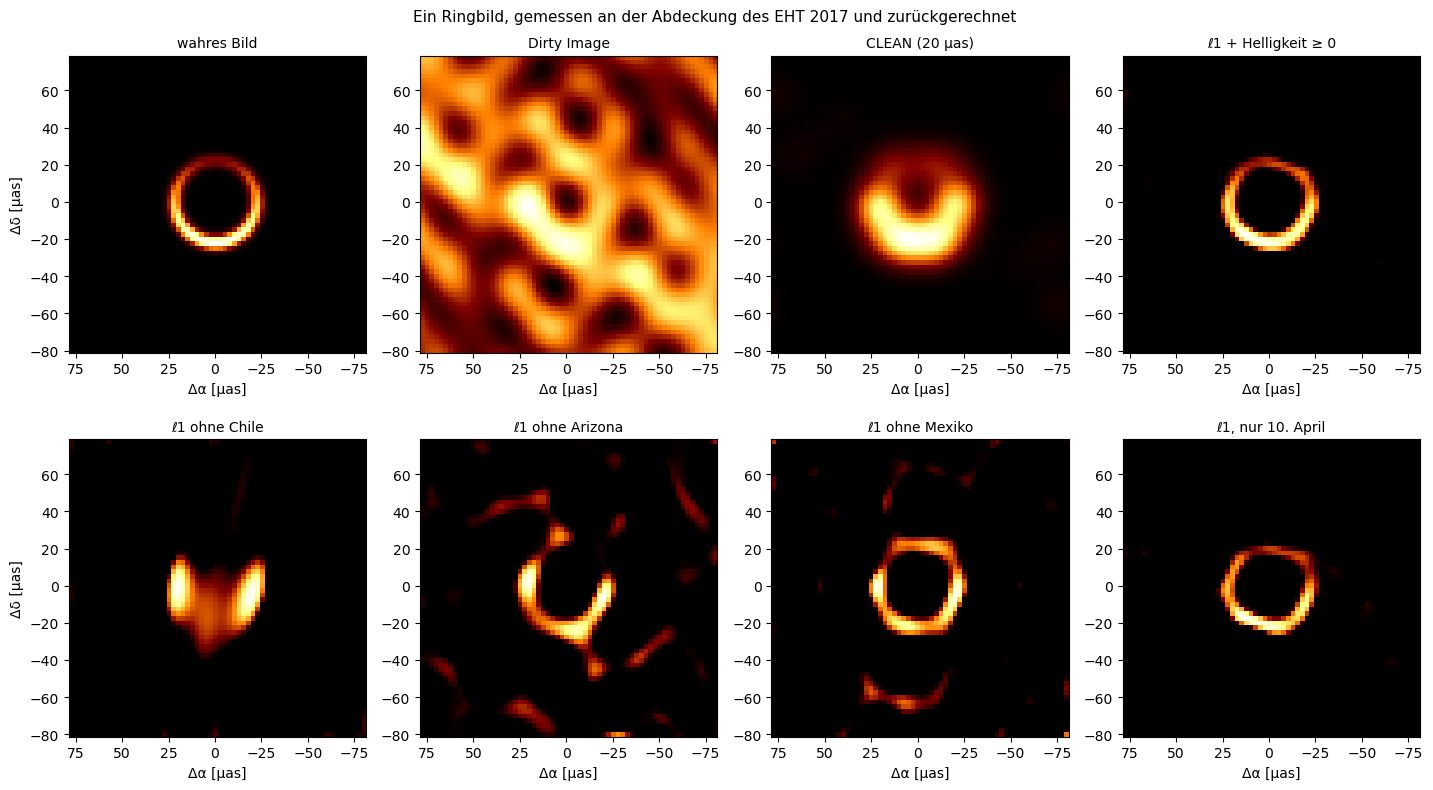

In [5]:
NOISE_JY = 0.01          # Rauschen je gemittelter Visibility (10 Minuten)
LAMBDA = 0.01            # Gewicht der ℓ1-Norm, relativ zum größten Wert von Aᵀy
NIGHT = "100"            # eine Nacht allein: "095", "096", "100" oder "101"
truth = eht.crescent(d_uas=fit["d"], width_uas=6, flux=0.6, contrast=0.6)     # Ring, im Süden heller
F, oben, unten = eht.compare(df, truth, NOISE_JY, LAMBDA, drop=("Chile", "Arizona", "Mexiko"), night=NIGHT)
eht.plot_images(F, [oben, unten], "Ein Ringbild, gemessen an der Abdeckung des EHT 2017 und zurückgerechnet")

**5. Ein Quantenzustand aus wenigen Pauli-Messungen**

Ein Zustand aus $q = 5$ Qubits ist durch $4^5 - 1 = 1023$ Erwartungswerte von Pauli-Strings wie $\langle XZIYZ\rangle$ bestimmt: $\rho = \tfrac{1}{d}\big(I + \sum_P \langle P\rangle\, P\big)$ mit $d = 2^q = 32$. Volle Tomographie misst alle. Hier wird nur eine zufällige Auswahl von $m$ Strings gemessen, jeder mit 1000 Schüssen, für zufällige reine Zustände (Mittel über 5). Zurückgerechnet wird linear, mit den fehlenden Erwartungswerten als null (das Gegenstück zum Dirty Image), und mit der Annahme Rang 1 (`tomography.low_rank`: Gradientenschritt, dann auf den größten Eigenvektor projizieren). Ein reiner Zustand hat nur $2d - 2 = 62$ reelle Parameter.

Die lineare Rekonstruktion wächst gerade mit dem gemessenen Anteil: Bei 400 von 1023 Strings hat sie eine Fidelity von 0.41, erst mit allen 1.00. Mit der Annahme Rang 1 hilft unter 150 Strings nichts, dann springt die Fidelity von 0.20 bei 150 über 0.76 bei 200 auf 1.00 bei 250 Strings, ein Phasenübergang wie in Schritt 2. Die Schwelle um 200 Strings liegt beim Drei- bis Vierfachen der 62 Parameter, ähnlich wie das 2.6- bis 3.9-Fache von $k$ in Schritt 2, und bei einem Fünftel aller Strings. Ein Lauf mit 4 Qubits (255 Strings, 30 Parameter) hatte die Schwelle zwischen 50 und 80 Strings. Das ist Compressed Sensing für Matrizen (Gross und andere, 2010): Für Rang $r$ genügen etwa $r\,d \log^2 d$ statt $d^2$ Messungen, und der Vorteil wächst mit der Zahl der Qubits.

5 Qubits: Dichtematrix mit 1023 reellen Zahlen, reiner Zustand mit 62 Parametern
  m =   20 Pauli-Strings (  2%): Fidelity linear 0.05, mit Rang 1 0.02
  m =   40 Pauli-Strings (  4%): Fidelity linear 0.07, mit Rang 1 0.03
  m =   62 Pauli-Strings (  6%): Fidelity linear 0.09, mit Rang 1 0.01
  m =  100 Pauli-Strings ( 10%): Fidelity linear 0.13, mit Rang 1 0.10
  m =  150 Pauli-Strings ( 15%): Fidelity linear 0.17, mit Rang 1 0.20
  m =  200 Pauli-Strings ( 20%): Fidelity linear 0.23, mit Rang 1 0.76
  m =  250 Pauli-Strings ( 24%): Fidelity linear 0.26, mit Rang 1 1.00
  m =  300 Pauli-Strings ( 29%): Fidelity linear 0.31, mit Rang 1 1.00
  m =  400 Pauli-Strings ( 39%): Fidelity linear 0.41, mit Rang 1 1.00
  m =  600 Pauli-Strings ( 59%): Fidelity linear 0.60, mit Rang 1 1.00
  m = 1023 Pauli-Strings (100%): Fidelity linear 1.00, mit Rang 1 1.00


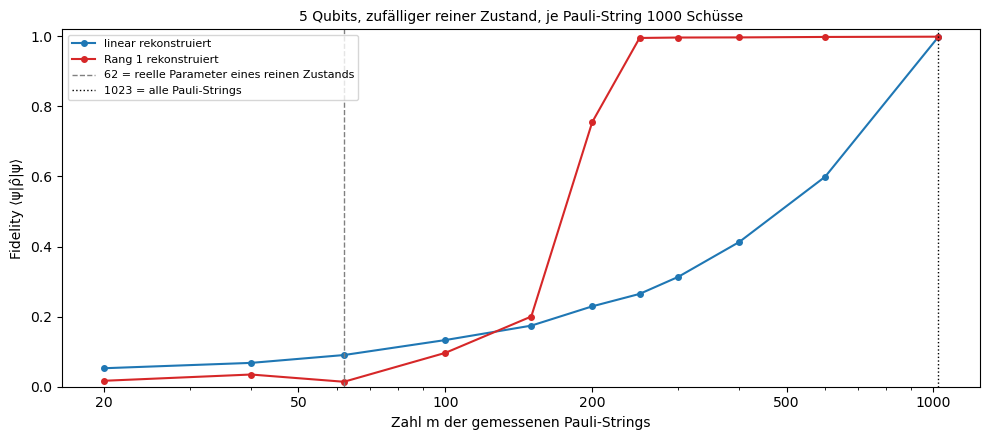

In [6]:
QUBITS, SHOTS = 5, 1000                                       # 5 Qubits: 1023 Pauli-Strings
MS = [20, 40, 62, 100, 150, 200, 250, 300, 400, 600, 1023]    # Zahl der gemessenen Strings
scan = tomography.tomography_scan(QUBITS, MS, SHOTS, trials=5)
tomography.plot_tomography(QUBITS, MS, scan, SHOTS)

**6. Classical Shadows: Eigenschaften statt Zustand**

Bei 10 Qubits hat die Dichtematrix schon $4^{10} - 1 \approx 10^6$ Pauli-Erwartungswerte, Tomographie ist aussichtslos. Oft will man aber nur einige Eigenschaften wissen, etwa Korrelationen. Classical Shadows (Huang, Kueng und Preskill, 2020) messen jedes Qubit in einer zufälligen Basis X, Y oder Z und speichern Basis und Ergebnis als Schnappschuss. Ein Pauli-String auf $w$ Qubits wird aus den Schnappschüssen geschätzt, in denen alle $w$ Basen passen (ein Anteil von $3^{-w}$), mit dem Faktor $3^w$ als Ausgleich. Simuliert wird der Grundzustand einer Ising-Kette aus 10 Qubits am kritischen Punkt $h = J$, exakt berechnet mit scipy (`tomography.ising_ground_state`), mit 20 000 Schnappschüssen.

Links liegen aus 2000 Schnappschüssen alle 45 Korrelationen $\langle Z_i Z_j\rangle$ im Mittel 0.05 neben dem exakten Wert (höchstens 0.15), genug, um den Abfall mit dem Abstand zu sehen. Rechts fällt der Fehler wie $1/\sqrt N$ und wächst mit dem Gewicht wie $\sqrt{3^w}$, so wie die gestrichelte Theorie $\sqrt{2/\pi}\,\sqrt{3^w/N}$ (der Faktor $\sqrt{2/\pi} \approx 0.8$ ist der mittlere Betrag einer Normalverteilung mit Streuung 1). Bei 10 000 Schnappschüssen sind es 0.013 für $w = 1$ und 0.067 für $w = 4$. Die Zahl der Qubits kommt in der Formel nicht vor: Wie viele Messungen man braucht, hängt hier von der Frage ab (Gewicht, Genauigkeit und laut Theorie nur logarithmisch von der Zahl der gesuchten Eigenschaften), nicht von der Größe des Zustands. Mit `H = 0.5` (geordnete Phase, ausprobiert) folgen die Fehler derselben Kurve.

10 Qubits: Der Zustand hat 2^10 = 1024 Amplituden, die Dichtematrix 1 048 575 Pauli-Erwartungswerte
Aus 2000 Schnappschüssen alle 45 Korrelationen ⟨Z_i Z_j⟩: mittlerer Fehler 0.052, größter 0.152
  Gewicht 1: Fehler 0.124 (N = 100), 0.068 (N = 300), 0.039 (N = 1000), 0.022 (N = 3000), 0.013 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.014
  Gewicht 2: Fehler 0.230 (N = 100), 0.142 (N = 300), 0.073 (N = 1000), 0.043 (N = 3000), 0.022 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.024
  Gewicht 3: Fehler 0.388 (N = 100), 0.234 (N = 300), 0.138 (N = 1000), 0.075 (N = 3000), 0.036 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.041
  Gewicht 4: Fehler 0.717 (N = 100), 0.442 (N = 300), 0.263 (N = 1000), 0.123 (N = 3000), 0.067 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.072


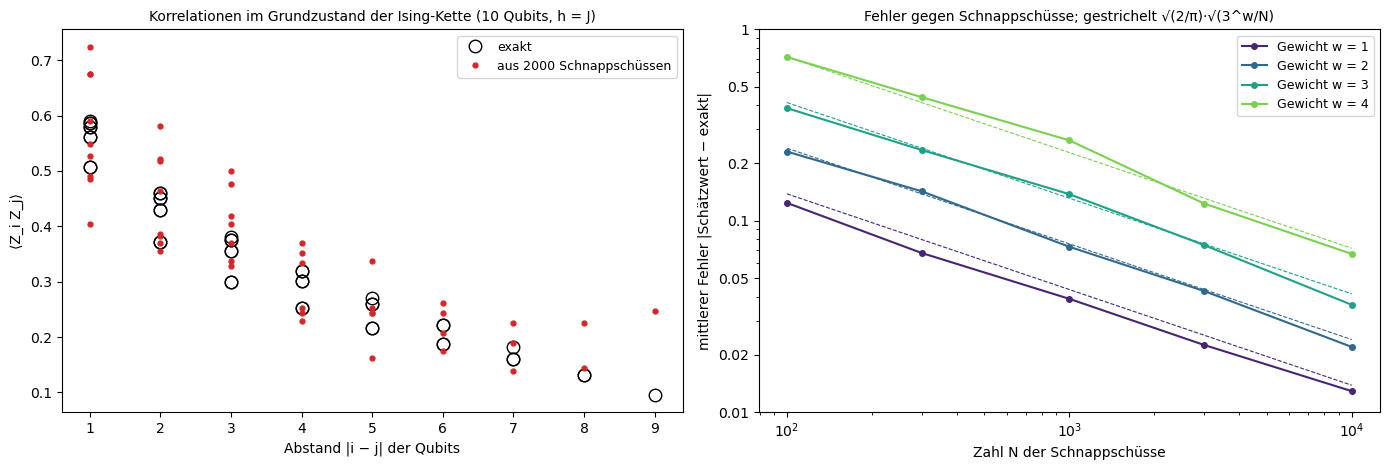

In [7]:
QUBITS, H = 10, 1.0          # Ising-Kette H = −J Σ Z_i Z_(i+1) − h Σ X_i; h = J ist der kritische Punkt
N_SHOW = 2000                # Schnappschüsse für das linke Bild
psi = tomography.ising_ground_state(QUBITS, h=H)
bases, outcomes = tomography.snapshots(psi, QUBITS, 20_000, seed=1)
zz_exact, zz_shadow, errors = tomography.shadow_study(psi, QUBITS, bases, outcomes, N_SHOW, ns=[100, 300, 1000, 3000, 10_000])